# Especialización en MLOps Engineer
## Módulo 1 · Sesión 1 — Introducción a MLOps y ciclo de vida de Machine Learning

**Objetivo general:** comprender qué es MLOps, qué problemas resuelve y cómo pasar de un experimento de *Machine Learning* a un flujo reproducible, evaluable, desplegable y monitoreable.

> El cuaderno está pensado para Google Colab y se puede ejecutar de arriba hacia abajo. No requiere Google Drive.

### Cómo estudiar esta sesión
Cada bloque sigue la misma lógica didáctica:
1. **concepto:** qué significa;
2. **razón de ingeniería:** por qué existe;
3. **implementación:** cómo se expresa en código;
4. **lectura del resultado:** qué debes comprobar;
5. **riesgo que evita:** qué podría salir mal sin esa práctica.

### Al finalizar podrás
- explicar **MLOps** y diferenciarlo de **Data Science**, **ML Engineering** y **DevOps**;
- reconocer las etapas del ciclo de vida de ML;
- separar correctamente entrenamiento, validación y prueba;
- construir un pipeline reproducible;
- registrar parámetros, métricas y versiones;
- serializar un modelo y validar sus entradas;
- interpretar una señal simple de *data drift*;
- definir *quality gates* antes de promover un modelo.

### Convención de los comentarios de código
Los comentarios explican **por qué** se ejecuta una instrucción, **qué supuesto introduce** o **qué error evita**. No son descripciones redundantes del tipo “importamos una librería”.

## 1. Glosario de siglas y términos

| Sigla / término | Significado | Para qué sirve |
|---|---|---|
| **AI** | *Artificial Intelligence* — Inteligencia Artificial | Campo general de sistemas que ejecutan tareas asociadas a inteligencia. |
| **ML** | *Machine Learning* — Aprendizaje Automático | Aprende patrones a partir de datos. |
| **MLOps** | *Machine Learning Operations* | Construir, probar, desplegar, operar y monitorear sistemas de ML con trazabilidad. |
| **DS** | *Data Science* — Ciencia de Datos | Análisis, modelado, experimentación y comunicación basada en datos. |
| **MLE** | *Machine Learning Engineering* | Convierte modelos en software robusto, eficiente y escalable. |
| **DevOps** | *Development + Operations* | Integra desarrollo de software y operaciones mediante automatización. |
| **CI** | *Continuous Integration* — Integración Continua | Integra cambios y ejecuta pruebas automáticamente. |
| **CD** | *Continuous Delivery/Deployment* — Entrega/Despliegue Continuo | Automatiza preparación o despliegue de versiones. |
| **API** | *Application Programming Interface* | Interfaz para que aplicaciones intercambien solicitudes y respuestas. |
| **KPI** | *Key Performance Indicator* | Indicador clave de desempeño del negocio o sistema. |
| **SLA** | *Service Level Agreement* | Compromiso medible de nivel de servicio. |
| **Drift** | Deriva | Cambio en la distribución de los datos o en su relación con el objetivo. |
| **Inferencia** | Uso de un modelo entrenado | Generar predicciones sobre nuevos datos. |
| **Artefacto** | Archivo producido por el pipeline | Modelo, métricas, esquema, gráfico, etc. |

**Idea central:** un modelo con una buena métrica dentro de un notebook todavía no es un sistema de producción.

## Ruta de aprendizaje de la sesión

**Parte 1 — Comprender:** qué es MLOps y qué problemas aparecen al pasar de experimento a producción.  
**Parte 2 — Construir:** entrenar un pipeline reproducible.  
**Parte 3 — Operar:** serializar, validar, monitorear y aplicar *quality gates*.  
**Parte 4 — Razonar:** comparar contra un baseline, estudiar thresholds y distinguir señales de drift.

La meta no es memorizar herramientas. La meta es poder explicar **qué problema resuelve cada componente** y qué riesgo aparece si lo omitimos.

## 2. ¿Qué problemas resuelve MLOps?

Un proyecto de ML real necesita más que entrenar un algoritmo:

1. **Datos trazables:** saber de dónde vienen y qué versión se utilizó.
2. **Código reproducible:** poder repetir el procedimiento.
3. **Experimentos comparables:** registrar parámetros, métricas y artefactos.
4. **Validación:** comprobar datos y desempeño antes de liberar.
5. **Despliegue controlado:** promover una versión aprobada.
6. **Monitoreo:** detectar errores, degradación y deriva.
7. **Retroalimentación:** decidir cuándo reentrenar, revertir o reemplazar el modelo.

### Diferencia entre disciplinas

| Disciplina | Pregunta principal | Entregable frecuente |
|---|---|---|
| **Data Science** | ¿Qué patrón o modelo explica/predice mejor? | análisis, notebook, modelo experimental |
| **ML Engineering** | ¿Cómo convierto el modelo en software confiable? | pipeline, paquete, servicio |
| **DevOps** | ¿Cómo despliego y opero software de forma estable? | automatización, infraestructura, CI/CD |
| **MLOps** | ¿Cómo opero todo el ciclo de ML con trazabilidad? | datos + modelos + pruebas + despliegue + monitoreo |

MLOps no sustituye estas disciplinas: las integra.

## 3. Ciclo de vida de Machine Learning

Una representación didáctica es:

**Datos → validación → preparación → entrenamiento → evaluación → registro → despliegue → inferencia → monitoreo → retroalimentación**

Dos principios:

- el ciclo es **iterativo**;
- en producción se monitorean métricas **técnicas, de datos, del modelo y del negocio**.

Ejemplos:
- técnicas: latencia, errores, uso de CPU o memoria;
- datos: nulos, rangos, categorías nuevas, deriva;
- modelo: precisión, *recall*, calibración;
- negocio: fraude evitado, conversión, coste, tiempo ahorrado.

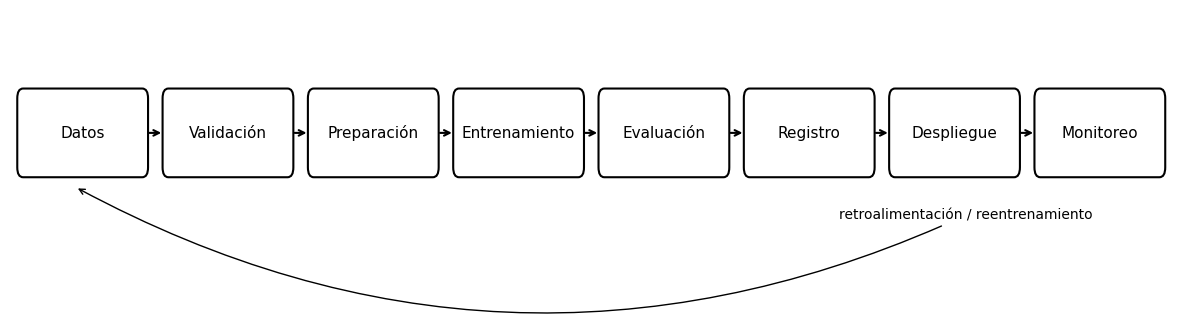

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Ordenamos las etapas según el flujo lógico de un sistema ML.
# No significa que el ciclo real sea estrictamente lineal: después de monitorear
# podemos volver a datos, preparación o entrenamiento.
stages = [
    "Datos", "Validación", "Preparación", "Entrenamiento",
    "Evaluación", "Registro", "Despliegue", "Monitoreo"
]

# Usamos una figura horizontal porque interesa visualizar continuidad entre etapas.
fig, ax = plt.subplots(figsize=(15, 3.2))
ax.set_xlim(0, len(stages))
ax.set_ylim(0, 1)
ax.axis("off")  # Quitamos ejes: aquí la figura comunica arquitectura, no magnitudes.

for i, stage in enumerate(stages):
    # Cada caja representa una responsabilidad separable del ciclo de vida.
    box = FancyBboxPatch(
        (i + 0.08, 0.35), 0.84, 0.30,
        boxstyle="round,pad=0.03,rounding_size=0.04",
        linewidth=1.5,
        fill=False,
    )
    ax.add_patch(box)
    ax.text(i + 0.50, 0.50, stage, ha="center", va="center", fontsize=11)

    # La flecha muestra el paso del artefacto o información a la etapa siguiente.
    if i < len(stages) - 1:
        ax.annotate(
            "",
            xy=(i + 1.06, 0.50),
            xytext=(i + 0.94, 0.50),
            arrowprops=dict(arrowstyle="->", lw=1.5),
        )

# Esta flecha inferior es la parte esencial del diagrama:
# producción genera evidencia que puede activar un nuevo ciclo de entrenamiento.
ax.annotate(
    "retroalimentación / reentrenamiento",
    xy=(0.45, 0.28),
    xytext=(7.45, 0.15),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=-0.25"),
    ha="right",
    fontsize=10,
)
plt.show()

## 4. Entornos: desarrollo, testing y producción

| Entorno | Finalidad | Características |
|---|---|---|
| **Development (DEV)** | Crear y experimentar | cambios frecuentes, depuración, muestras de datos |
| **Testing / Staging (TEST)** | Validar antes de liberar | pruebas automáticas y configuración cercana a producción |
| **Production (PROD)** | Servir usuarios reales | estabilidad, seguridad, observabilidad y control de cambios |

**Principio:** el mismo código debería comportarse de forma consistente. Las diferencias entre entornos se gestionan principalmente mediante configuración, credenciales e infraestructura.

# 5. Proyecto práctico de extremo a extremo

Usaremos el dataset de diagnóstico de cáncer de mama incluido en `scikit-learn`.

**Uso exclusivamente educativo:** este cuaderno no debe utilizarse para decisiones médicas.

### Flujo práctico
1. cargar y revisar datos;
2. crear train/validation/test;
3. construir un pipeline;
4. entrenar;
5. evaluar;
6. registrar un experimento;
7. guardar artefactos;
8. recargar el modelo;
9. ejecutar inferencia;
10. validar entradas;
11. observar una señal simple de deriva.

In [2]:
# Librerías estándar para serialización, rutas, plataforma y marcas de tiempo.
import json
import platform
from pathlib import Path
from datetime import datetime, timezone

# Herramientas numéricas y tabulares.
import joblib
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt

# Dataset local incluido en scikit-learn: evita depender de una URL externa.
from sklearn.datasets import load_breast_cancer

# Utilidad para crear particiones reproducibles del dataset.
from sklearn.model_selection import train_test_split

# Pipeline evita separar manualmente preprocesamiento y modelo.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Métricas complementarias: ninguna describe por sí sola todo el desempeño.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    classification_report,
)

# Una semilla fija hace determinista la partición aleatoria del ejemplo.
# Reproducibilidad NO significa que todo ML siempre sea perfectamente determinista,
# pero controlar las fuentes de aleatoriedad reduce variaciones innecesarias.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Registramos versiones porque un experimento no está definido solo por el código:
# también depende de la versión de las librerías que ejecutan ese código.
print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)

Python: 3.13.16
NumPy: 2.1.3
pandas: 2.2.3
scikit-learn: 1.6.1
matplotlib: 3.10.0


### ¿Por qué registrar versiones?

Una misma base de código puede comportarse de forma distinta con versiones diferentes de librerías. Registrar el entorno ayuda a responder:

- ¿con qué versión se entrenó?
- ¿podemos reproducir el experimento?
- ¿un cambio de dependencia alteró el resultado?

### Antes de cargar los datos: features frente a target
`X` contendrá las variables que el modelo **puede observar** y `y` la respuesta que queremos predecir.

Separarlas desde el principio ayuda a evitar una de las fugas más graves: introducir accidentalmente la variable objetivo dentro de las variables predictoras.

**Qué debes comprobar al ejecutar:** número de filas, número de variables y nombres de las clases.

In [3]:
# as_frame=True conserva nombres de columnas y devuelve estructuras pandas.
bundle = load_breast_cancer(as_frame=True)

# X contiene SOLO las variables predictoras.
X = bundle.data.copy()

# y contiene la etiqueta que queremos predecir.
y = bundle.target.copy()

# Reconstruimos temporalmente una tabla completa para inspección y controles.
# No entrenaremos el modelo pasando df directamente.
df = X.copy()
df["target"] = y

# Verificamos dimensiones y codificación de clases.
print("Filas:", len(df))
print("Variables predictoras:", X.shape[1])
print("Clases:", dict(enumerate(bundle.target_names)))

# La inspección visual ayuda a detectar problemas obvios de esquema o escala.
display(df.head())

Filas: 569
Variables predictoras: 30
Clases: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


### Control de calidad antes de modelar
Un pipeline profesional intenta fallar **antes** de entrenar cuando detecta datos incompatibles.

Aquí revisamos cuatro propiedades mínimas: tamaño, nulos, duplicados y balance de clases. En producción también validaríamos tipos, rangos, categorías permitidas, unicidad de claves y reglas de negocio.

In [4]:
# Convertimos los resultados a tipos nativos de Python para facilitar su serialización posterior.
quality_report = {
    "rows": int(df.shape[0]),
    "columns": int(df.shape[1]),

    # Cuenta todas las celdas faltantes, no solo filas con algún faltante.
    "missing_cells": int(df.isna().sum().sum()),

    # Filas completamente idénticas pueden sobreponderar observaciones repetidas.
    "duplicated_rows": int(df.duplicated().sum()),

    # normalize=True convierte conteos en proporciones: útil para detectar desbalance.
    "target_distribution": (
        df["target"].value_counts(normalize=True).sort_index().to_dict()
    ),
}

quality_report

{'rows': 569,
 'columns': 31,
 'missing_cells': 0,
 'duplicated_rows': 0,
 'target_distribution': {0: 0.37258347978910367, 1: 0.6274165202108963}}

## 6. Entrenamiento, validación y prueba

- **Train:** ajusta parámetros del modelo.
- **Validation:** compara alternativas o decisiones de modelado.
- **Test:** estimación final sobre datos no utilizados durante el ajuste.

Usaremos aproximadamente **70% / 15% / 15%** y `stratify` para mantener la proporción de clases.

### Por qué hacemos tres particiones
- **Train:** aprende parámetros.
- **Validation:** permite decidir entre alternativas.
- **Test:** se reserva hasta el final para estimar desempeño fuera del proceso de selección.

Si utilizas test repetidamente para elegir modelos, deja de ser una evaluación final independiente.

In [5]:
# Primera división: 70% train y 30% temporal.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    # stratify conserva aproximadamente la proporción de clases en cada bloque.
    stratify=y,
)

# Segunda división: el 30% temporal se divide en dos mitades (~15% y ~15%).
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp,
)

# Resumen explícito: siempre conviene verificar que las proporciones reales
# correspondan con lo que creemos haber configurado.
splits = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "n": [len(X_train), len(X_valid), len(X_test)],
    "proportion": [
        len(X_train) / len(X),
        len(X_valid) / len(X),
        len(X_test) / len(X),
    ],
})
display(splits)

,split,n,proportion
0,train,398,0.699473
1,validation,85,0.149385
2,test,86,0.151142


## 7. Pipeline de entrenamiento

`Pipeline` encadena transformaciones y estimador.

1. `StandardScaler`: estandariza variables.
2. `LogisticRegression`: ajusta un clasificador binario.

El pipeline reduce el riesgo de **data leakage** — fuga de información desde validación/prueba hacia entrenamiento.

### El punto crítico del Pipeline
`StandardScaler` debe aprender media y desviación **solo con train**. Al encapsularlo dentro de `Pipeline`, `fit(X_train, y_train)` ajusta primero el escalador con train y después el clasificador.

Esto evita que estadísticas de validación o test se filtren hacia el entrenamiento.

In [6]:
# El Pipeline empaqueta preprocesamiento + modelo en un único objeto versionable.
model = Pipeline(steps=[
    (
        "scaler",
        # Estandariza variables para que magnitudes muy distintas no dominen la optimización.
        StandardScaler(),
    ),
    (
        "classifier",
        LogisticRegression(
            # Damos margen suficiente al optimizador para converger.
            max_iter=3000,
            random_state=RANDOM_STATE,
        ),
    ),
])

# fit() ajusta el scaler con X_train y, usando esa transformación, ajusta el clasificador.
# Validación y test NO participan en este ajuste.
model.fit(X_train, y_train)
print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


### Evaluar significa responder preguntas diferentes
`accuracy`, `precision`, `recall`, `F1` y `ROC AUC` no son sinónimos. Cada una enfatiza una propiedad distinta.

La función que sigue devuelve un diccionario porque luego podremos persistirlo como metadato de un experimento.

In [8]:
def evaluate_classifier(model, X_eval, y_eval):
    """Calcula métricas complementarias sobre un conjunto que NO modifica el modelo."""

    # Clase final después de aplicar el umbral interno del clasificador.
    pred = model.predict(X_eval)

    # Probabilidad estimada de la clase positiva; ROC AUC necesita scores continuos.
    proba = model.predict_proba(X_eval)[:, 1]

    return {
        "accuracy": accuracy_score(y_eval, pred),
        "precision": precision_score(y_eval, pred, zero_division=0),
        "recall": recall_score(y_eval, pred, zero_division=0),
        "f1": f1_score(y_eval, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_eval, proba),
    }

# Validación sirve para juzgar decisiones de modelado.
valid_metrics = evaluate_classifier(model, X_valid, y_valid)

# Test se interpreta como evaluación final después de cerrar decisiones.
test_metrics = evaluate_classifier(model, X_test, y_test)

print("Métricas de validación")
display(pd.Series(valid_metrics).to_frame("valor").round(4))
print("Métricas de prueba")
display(pd.Series(test_metrics).to_frame("valor").round(4))

Métricas de validación


,valor
accuracy,0.9882
precision,1.0000
recall,0.9811
f1,0.9905
roc_auc,1.0000


Métricas de prueba


,valor
accuracy,0.9884
precision,0.9818
recall,1.0000
f1,0.9908
roc_auc,0.9954


### Siglas y métricas

- **Accuracy:** proporción total de predicciones correctas.
- **Precision:** entre positivos predichos, cuántos son positivos reales.
- **Recall:** entre positivos reales, cuántos detectó el modelo.
- **F1-score:** media armónica de *precision* y *recall*.
- **ROC AUC:** área bajo la curva *Receiver Operating Characteristic*; resume discriminación entre clases a diferentes umbrales.

La métrica adecuada depende del coste de los errores y del objetivo.

### Matriz de confusión: dónde se equivoca el modelo
Una métrica agregada puede ocultar el tipo de error. La matriz de confusión permite ver verdaderos/falsos positivos y negativos.

En un problema real, el coste de cada error debe decidirse con el dominio, no solamente con estadística.

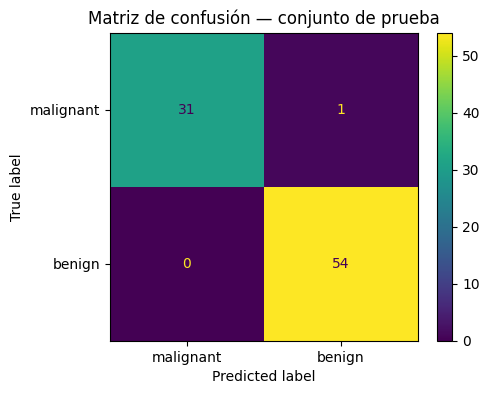

              precision    recall  f1-score   support

   malignant     1.0000    0.9688    0.9841        32
      benign     0.9818    1.0000    0.9908        54

    accuracy                         0.9884        86
   macro avg     0.9909    0.9844    0.9875        86
weighted avg     0.9886    0.9884    0.9883        86



In [9]:
# Generamos clases predichas sobre test una única vez para inspeccionar tipos de error.
pred_test = model.predict(X_test)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_test,
    display_labels=bundle.target_names,
    ax=ax,
)
ax.set_title("Matriz de confusión — conjunto de prueba")
plt.show()

# classification_report desglosa precision, recall y F1 por clase.
print(classification_report(
    y_test,
    pred_test,
    target_names=bundle.target_names,
    digits=4,
))

## 8. Registro mínimo de experimentos

Una plataforma como **MLflow** automatiza el *experiment tracking*. Conceptualmente interesa conservar:

- identificador de corrida;
- fecha y hora;
- dataset;
- parámetros;
- métricas;
- versiones de software;
- artefactos.

Aquí lo haremos con JSON para entender qué se registra.

### Tracking sin herramienta especializada
MLflow automatiza esta tarea, pero primero conviene entender el objeto que queremos registrar: identificación de corrida, fecha, datos, modelo, métricas, semilla y versiones.

El JSON siguiente funciona como un *run record* mínimo y legible.

In [11]:
# Guardamos artefactos en una carpeta dedicada, no mezclados con código o datos.
ARTIFACT_DIR = Path.cwd() / "mlops_session1_artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# UTC evita ambigüedad cuando distintos servidores trabajan en zonas horarias diferentes.
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

# Registro mínimo de una corrida: suficiente para responder qué se ejecutó y con qué resultado.
experiment = {
    "run_id": run_id,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "random_state": RANDOM_STATE,
    "model": "StandardScaler + LogisticRegression",
    "dataset": "sklearn.datasets.load_breast_cancer",
    "train_rows": len(X_train),
    "validation_rows": len(X_valid),
    "test_rows": len(X_test),
    "validation_metrics": valid_metrics,
    "test_metrics": test_metrics,
    "versions": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
    },
}

experiment_path = ARTIFACT_DIR / f"experiment_{run_id}.json"
experiment_path.write_text(json.dumps(experiment, indent=2), encoding="utf-8")
print("Registro creado:", experiment_path)

Registro creado: /content/mlops_session1_artifacts/experiment_20261008T052950Z.json


## 9. Serialización del modelo

**Serializar** significa guardar el objeto entrenado para reutilizarlo sin volver a entrenar.

Usaremos `joblib`, habitual para modelos de `scikit-learn`. Un artefacto profesional también debe tener versión, esquema y metadatos.

### Artefacto del modelo y contrato de entrada
Guardar únicamente “el algoritmo” es insuficiente. Necesitamos guardar el pipeline completo y describir qué columnas espera.

El `schema.json` actúa como contrato entre entrenamiento e inferencia.

In [12]:
model_path = ARTIFACT_DIR / "model.joblib"
schema_path = ARTIFACT_DIR / "schema.json"

# joblib serializa TODO el Pipeline: parámetros del scaler + pesos del clasificador.
# Esto evita reimplementar el preprocesamiento durante inferencia.
joblib.dump(model, model_path)

# El esquema permite validar qué columnas espera el artefacto antes de invocarlo.
schema = {
    "feature_names": X.columns.tolist(),
    "n_features": X.shape[1],
    "target_name": "target",
}
schema_path.write_text(json.dumps(schema, indent=2), encoding="utf-8")

print("Modelo:", model_path)
print("Esquema:", schema_path)

Modelo: /content/mlops_session1_artifacts/model.joblib
Esquema: /content/mlops_session1_artifacts/schema.json


### Simular una aplicación de inferencia
Recargar el modelo desde disco demuestra que la predicción ya no depende del objeto que quedó en memoria durante el entrenamiento.

Ese patrón se parece más a producción: un proceso entrena y otro proceso, quizá en otro servidor, consume el artefacto.

In [13]:
# Abrimos el artefacto como lo haría un proceso distinto al de entrenamiento.
loaded_model = joblib.load(model_path)

# Conservamos formato DataFrame para mantener nombres de columnas.
sample = X_test.iloc[[0]].copy()

# Clase discreta para una decisión final.
pred_class = int(loaded_model.predict(sample)[0])

# Probabilidad de clase 1 para disponer también de una medida continua de confianza.
pred_probability = float(loaded_model.predict_proba(sample)[0, 1])

print("Predicción de clase:", pred_class)
print("Probabilidad de la clase 1:", round(pred_probability, 4))

Predicción de clase: 1
Probabilidad de la clase 1: 0.9916


## 10. Validación de entrada

Un servicio de inferencia debería comprobar como mínimo:

- columnas requeridas;
- columnas inesperadas;
- valores faltantes;
- tipos de datos;
- rangos plausibles.

### Validación de entrada: fallar temprano y con contexto
Es preferible responder “falta la columna X” antes que enviar datos mal formados al modelo y obtener un error difícil de interpretar.

Esta función implementa un contrato mínimo de columnas, nulos y tipos.

In [14]:
def validate_input_frame(frame: pd.DataFrame, expected_features: list[str]) -> None:
    """Valida el contrato mínimo de entrada antes de llamar al modelo."""

    # Detectamos columnas obligatorias ausentes.
    missing = sorted(set(expected_features) - set(frame.columns))

    # Detectamos columnas nuevas que el modelo nunca vio.
    extra = sorted(set(frame.columns) - set(expected_features))

    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")
    if extra:
        raise ValueError(f"Se recibieron columnas no esperadas: {extra}")

    # Preferimos rechazar nulos aquí y dar un mensaje claro, en lugar de fallar más tarde.
    if frame[expected_features].isna().any().any():
        raise ValueError("La entrada contiene valores faltantes.")

    # El modelo fue entrenado con columnas numéricas; un string puede indicar un cambio de esquema.
    non_numeric = [
        col for col in expected_features
        if not pd.api.types.is_numeric_dtype(frame[col])
    ]
    if non_numeric:
        raise TypeError(f"Estas columnas deberían ser numéricas: {non_numeric}")

validate_input_frame(sample, X.columns.tolist())
print("Entrada válida.")

Entrada válida.


## 11. Monitoreo y data drift

**Data drift**: la distribución de las variables de entrada cambia respecto a una referencia.

Esto no demuestra por sí solo que el modelo falle, pero es una señal que merece revisión.

Usaremos **PSI — Population Stability Index**:

$PSI = \sum_i (q_i - p_i)\ln\left(\frac{q_i}{p_i}\right)$

donde $p_i$ es la proporción de referencia y $q_i$ la proporción actual en el intervalo $i$.

Los umbrales de PSI son heurísticos y dependen del contexto.

### Drift no significa automáticamente “modelo malo”
El *data drift* pregunta si la distribución de entrada cambió. El *performance drift* pregunta si el modelo perdió desempeño. Son fenómenos diferentes.

PSI se usa aquí como señal didáctica para comparar una distribución de referencia con una distribución reciente.

In [15]:
def population_stability_index(reference, current, bins=10, epsilon=1e-6):
    """Calcula PSI usando cuantiles de la distribución de referencia."""

    reference = np.asarray(reference, dtype=float)
    current = np.asarray(current, dtype=float)

    # Los cuantiles de la referencia definen los bins; no dejamos que los datos actuales
    # redefinan la línea base porque eso haría la comparación inconsistente.
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        # Variable casi constante: no hay suficientes cortes útiles para comparar.
        return 0.0

    # Cubrimos valores actuales que caigan fuera del rango observado en entrenamiento.
    edges[0] = -np.inf
    edges[-1] = np.inf

    ref_counts, _ = np.histogram(reference, bins=edges)
    cur_counts, _ = np.histogram(current, bins=edges)

    ref_pct = ref_counts / max(ref_counts.sum(), 1)
    cur_pct = cur_counts / max(cur_counts.sum(), 1)

    # Evitamos log(0) y divisiones por cero; epsilon es una corrección numérica, no conceptual.
    ref_pct = np.clip(ref_pct, epsilon, None)
    cur_pct = np.clip(cur_pct, epsilon, None)

    return float(np.sum((cur_pct - ref_pct) * np.log(cur_pct / ref_pct)))

feature = "mean radius"
reference_values = X_train[feature].to_numpy()

# Provocamos drift artificial multiplicando la variable por 1.20.
# En producción esta serie vendría de observaciones nuevas reales.
simulated_current = X_test[feature].to_numpy() * 1.20

psi_value = population_stability_index(reference_values, simulated_current)
print(f"PSI para '{feature}': {psi_value:.4f}")

PSI para 'mean radius': 1.6031


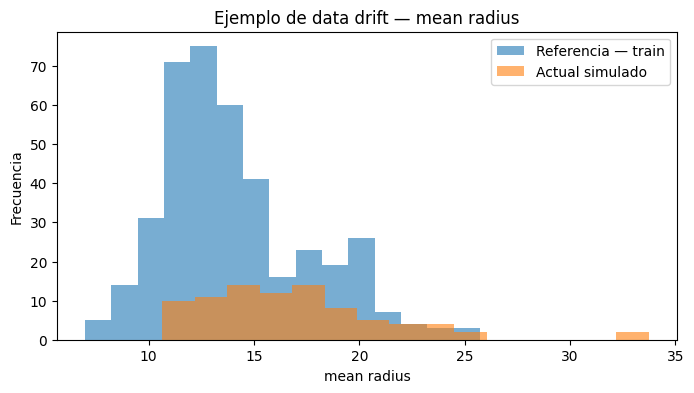

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(reference_values, bins=15, alpha=0.6, label="Referencia — train")
ax.hist(simulated_current, bins=15, alpha=0.6, label="Actual simulado")
ax.set_title(f"Ejemplo de data drift — {feature}")
ax.set_xlabel(feature)
ax.set_ylabel("Frecuencia")
ax.legend()
plt.show()

## 12. Quality gates

Un **quality gate** es una condición automática que debe cumplirse antes de promover una versión.

Ejemplos:
- no faltan columnas;
- no hay nulos inesperados;
- una métrica mínima se alcanza;
- existe el artefacto;
- las pruebas pasan.

El umbral correcto se define según el caso de uso.

### Convertir criterios en quality gates
Un criterio que vive solo en una diapositiva no protege un pipeline. Un *quality gate* convierte una regla en una condición que puede detener automáticamente la promoción.

El valor `0.90` del ejemplo es didáctico; en producción debe justificarse por baseline, coste de errores y riesgo.

In [32]:
quality_gates = {
    # Un dataset base con nulos inesperados no debería continuar sin una política explícita.
    "no_missing_values": df.isna().sum().sum() == 0,

    # El schema debe describir exactamente las features usadas por el modelo.
    "schema_has_expected_features": len(schema["feature_names"]) == X.shape[1],

    # Si el archivo no existe, no hay artefacto que desplegar.
    "model_artifact_exists": model_path.exists(),

    # Umbral DIDÁCTICO; en producción debe venir de una política justificada.
    "test_roc_auc_at_least_0_90": test_metrics["roc_auc"] >= 0.90,
}

display(pd.Series(quality_gates, name="passed").to_frame())

# all(...) obliga a que todas las condiciones sean True.
# Fallar aquí impide que un pipeline automatizado promueva una versión inválida.
if not all(quality_gates.values()):
    raise RuntimeError("Uno o más quality gates no se cumplieron.")

print("Todos los quality gates se cumplieron.")

,passed
no_missing_values,True
schema_has_expected_features,True
model_artifact_exists,True
test_roc_auc_at_least_0_90,True


Todos los quality gates se cumplieron.


## 13. Componentes de una arquitectura MLOps

Una solución real puede integrar:

- fuentes de datos;
- validación y transformación;
- *feature store* opcional;
- entrenamiento;
- *experiment tracking*;
- *model registry*;
- CI/CD;
- servicio de inferencia;
- monitoreo y observabilidad;
- alertas y reentrenamiento.

Más adelante herramientas como **MLflow**, **FastAPI**, **Docker**, **Apache Airflow**, **GitHub Actions**, **Google Cloud** o **Vertex AI** pueden implementar estas capas.

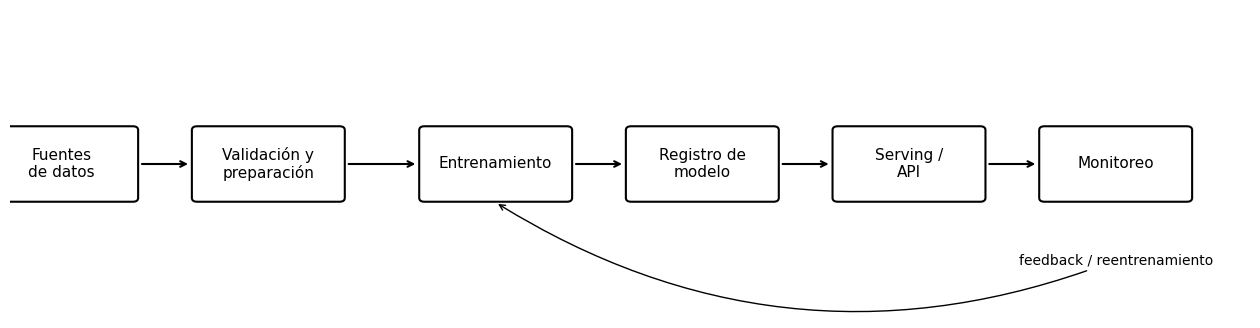

In [18]:
components = [
    ("Fuentes\nde datos", 0.5, 2.0),
    ("Validación y\npreparación", 2.5, 2.0),
    ("Entrenamiento", 4.7, 2.0),
    ("Registro de\nmodelo", 6.7, 2.0),
    ("Serving /\nAPI", 8.7, 2.0),
    ("Monitoreo", 10.7, 2.0),
]

fig, ax = plt.subplots(figsize=(16, 4))
ax.set_xlim(0, 12)
ax.set_ylim(0, 4)
ax.axis("off")

for label, x, y in components:
    rect = FancyBboxPatch(
        (x - 0.7, y - 0.45), 1.4, 0.9,
        boxstyle="round,pad=0.04,rounding_size=0.05",
        fill=False, linewidth=1.5
    )
    ax.add_patch(rect)
    ax.text(x, y, label, ha="center", va="center", fontsize=11)

for i in range(len(components) - 1):
    x1 = components[i][1] + 0.75
    x2 = components[i + 1][1] - 0.75
    ax.annotate("", xy=(x2, 2), xytext=(x1, 2),
                arrowprops=dict(arrowstyle="->", lw=1.5))

ax.annotate(
    "feedback / reentrenamiento",
    xy=(4.7, 1.5), xytext=(10.7, 0.7),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=-0.25"),
    ha="center"
)
plt.show()

## 14. Qué construimos

| Necesidad MLOps | Implementación didáctica |
|---|---|
| reproducibilidad | semilla fija + versiones |
| calidad de datos | nulos, duplicados, esquema |
| separación correcta | train / validation / test |
| pipeline | `Pipeline` de scikit-learn |
| tracking | JSON de experimento |
| artefacto | `model.joblib` |
| contrato de entrada | `schema.json` |
| monitoreo | PSI |
| promoción | quality gates |

## 15. Ejercicios propuestos

1. Sustituye `LogisticRegression` por `RandomForestClassifier`.
2. Registra hiperparámetros con `model.get_params()`.
3. Ejecuta dos experimentos y compáralos.
4. Calcula PSI para tres variables.
5. Define una política de promoción del modelo.
6. Explica por qué no se debe elegir el modelo usando el conjunto de test.

### Preguntas de comprobación
- ¿Por qué un modelo entrenado no es todavía un sistema MLOps?
- ¿Qué diferencia existe entre validación y prueba?
- ¿Qué debe versionarse además del código?
- ¿Qué señales deben observarse después del despliegue?
- ¿Por qué drift no equivale necesariamente a pérdida de desempeño?

### Respuestas a las Preguntas de Comprobación

<details>
<summary><b>Ver mis respuestas (clic en el triangulito)</b></summary>

<br>

1. **¿Por qué un modelo entrenado no es todavía un sistema MLOps?**
Porque un modelo aislado en un notebook no tiene código reproducible, datos trazables, validación automatizada ni despliegue controlado. En producción, factores como la latencia, la infraestructura y el valor de negocio son tan importantes como el algoritmo.

2. **¿Qué diferencia existe entre validación y prueba?**
La *Validación* es el campo de pruebas: se usa para comparar alternativas, ajustar hiperparámetros y **elegir** el mejor modelo. La *Prueba (Test)* es intocable: solo se usa al final para estimar el desempeño real del modelo ganador sobre datos 100% nuevos.

3. **¿Qué debe versionarse además del código?**
Para tener reproducibilidad total, se debe registrar: identificador de la corrida, la versión exacta del *dataset*, los hiperparámetros, las métricas, las versiones de las librerías, el esquema de entrada (`schema.json`) y el archivo serializado del modelo (`model.joblib`).

4. **¿Qué señales deben observarse después del despliegue?**
Se deben monitorear cuatro frentes: métricas **técnicas** (latencia, uso de CPU), métricas **de datos** (porcentaje de nulos, deriva de datos), métricas **del modelo** (precisión, recall) y métricas **del negocio** (impacto económico, fraudes evitados).

5. **¿Por qué drift no equivale necesariamente a pérdida de desempeño?**
El *data drift* solo indica que la distribución de los datos de entrada cambió respecto al entrenamiento (es una alerta). El modelo aún podría ser capaz de predecir correctamente. Para confirmar una pérdida real de desempeño (*performance drift*), se deben contrastar las predicciones con las etiquetas reales cuando estén disponibles.

</details>

### 1. Sustituye LogisticRegression por RandomForestClassifier

In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Asumimos que RANDOM_STATE = 42 y X_train, y_train ya están cargados en tu entorno

model_rf = Pipeline(steps=[
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        RandomForestClassifier(random_state=RANDOM_STATE)
    )
])

# Ajustamos el scaler y el ensamble
model_rf.fit(X_train, y_train)
print("Modelo RandomForest entrenado correctamente.")

Modelo RandomForest entrenado correctamente.


### 2. Registra hiperparámetros con model.get_params()

In [36]:
pipeline_params = model_rf.get_params()
rf_params = {k: v for k, v in pipeline_params.items() if k.startswith('classifier__')}

### 3. Ejecuta dos experimentos y compáralos

In [30]:
# Ejecuta dos experimentos y compáralos
import pandas as pd

# 1. Evaluamos el nuevo modelo Random Forest en el conjunto de prueba
rf_test_metrics = evaluate_classifier(model_rf, X_test, y_test)

# 2. Creamos un DataFrame cruzando el resultado nuevo con el del modelo original
# (test_metrics ya contiene los datos de la Regresión Logística del punto 7)
comparacion_experimentos = pd.DataFrame({
    "Regresión Logística": test_metrics,
    "Random Forest": rf_test_metrics
}).T

# 3. Mostramos la comparativa redondeada a 4 decimales para facilitar la lectura
display(comparacion_experimentos.round(4))

,accuracy,precision,recall,f1,roc_auc
Regresión Logística,0.9884,0.9818,1.0000,0.9908,0.9954
Random Forest,0.8837,0.8929,0.9259,0.9091,0.9809


La Regresión Logística superó al Random Forest en todas las métricas evaluadas. El punto más crítico de esta comparativa es la caída del recall de 1.0000 a 0.9259. En un caso de uso médico como el diagnóstico de cáncer, perder detecciones (aumentar los falsos negativos) tiene un costo inaceptable, por lo que el modelo lineal, más simple, sigue siendo la mejor opción para este conjunto de datos específico.

### 4. Calcula PSI para tres variables

In [31]:
# Calcula PSI para tres variables.
import pandas as pd

# 1. Seleccionamos exactamente 3 variables para monitorear
features_to_monitor = [
    "mean texture",
    "mean perimeter",
    "mean area"
]

drift_rows = []

for feature_name in features_to_monitor:
    # Referencia: Distribución observada durante el entrenamiento
    reference = X_train[feature_name].to_numpy()

    # Actual: Simulamos un desplazamiento del 8% sobre el conjunto de test para forzar el drift
    current = X_test[feature_name].to_numpy() * 1.08

    # Calculamos el PSI con la función del entorno
    psi = population_stability_index(reference, current)

    drift_rows.append({
        "feature": feature_name,
        "psi": psi
    })

# 2. Formateamos y mostramos la tabla de resultados
drift_table = pd.DataFrame(drift_rows).sort_values("psi", ascending=False).reset_index(drop=True)
display(drift_table.round(4))

,feature,psi
0,mean texture,0.3383
1,mean area,0.2013
2,mean perimeter,0.1730


Clave de MLOps: el cálculo del PSI (Data Drift) no pertenece ni a la Regresión Logística ni al Random Forest. Evalúa exclusivamente cómo cambia la distribución de los datos de entrada (las variables en X), sin importar qué algoritmo los consuma después.

Los resultados muestran que mean texture (0.3383) y mean area (0.2013) superaron el umbral crítico de 0.2, ubicándose en la zona roja de alerta. Por otro lado, mean perimeter (0.1730) se encuentra en la zona amarilla, indicando un cambio moderado

### 5. Definir una política de promoción del modelo (Quality Gates)

Un **quality gate** es una condición automática que debe cumplirse rígidamente antes de promover una nueva versión de un modelo a producción. En un contexto médico como el diagnóstico de cáncer de mama, priorizar el *recall* es vital para evitar los falsos negativos (decirle a un paciente enfermo que está sano).   

Nuestra política de promoción formal y automatizable quedaría estructurada de la siguiente manera:

* **Integridad de entrada:** El conjunto de datos no debe contener valores nulos y el esquema debe tener exactamente las características esperadas por el contrato.
* **Disponibilidad de artefactos:** El archivo serializado (`model.joblib`) debe generarse correctamente y existir en la ruta de artefactos asignada.
* **Métrica crítica de negocio (Recall):** El *Recall* en el conjunto de prueba debe ser **>= 0.98**. Esta regla es la que rechazaría automáticamente el despliegue del Random Forest (que obtuvo 0.9259) y aprobaría la Regresión Logística original.
* **Desempeño general (ROC AUC):** El área bajo la curva ROC AUC en el conjunto de prueba debe ser **>= 0.90** para asegurar una correcta capacidad de discriminación entre clases.

### 6. ¿Por qué no se debe elegir el modelo usando el conjunto de test?

Porque **contamina la evaluación final**. Si usamos el conjunto de prueba para tomar decisiones, este deja de ser una evaluación independiente y se convierte en parte del entrenamiento (sobreajuste indirecto o *Data Leakage*).

* **El rol estricto de cada conjunto:**
  * **Train:** El modelo aprende los patrones.
  * **Validation:** El científico de datos compara modelos y ajusta parámetros (**Aquí se elige el modelo**).
  * **Test:** Simula el mundo real evaluando el modelo final con datos 100% inéditos.

* **En conclusión:** Si eliges el modelo porque sacó mejor puntaje en el test, lo estás optimizando para ese subconjunto específico. Obtendrás métricas falsamente optimistas y el modelo colapsará cuando enfrente datos verdaderamente nuevos en producción.

## Errores frecuentes que esta sesión intenta prevenir
- **Escalar antes del split:** filtra información estadística de test hacia train.
- **Elegir el modelo mirando test repetidamente:** test deja de ser una evaluación independiente.
- **Guardar solo el clasificador:** inferencia puede aplicar un preprocesamiento diferente.
- **No registrar versiones:** una corrida puede dejar de ser reproducible.
- **Interpretar drift como degradación automática:** primero hay que medir desempeño cuando las etiquetas estén disponibles.
- **Monitorear solo accuracy:** producción también necesita latencia, errores, disponibilidad, coste y métricas de negocio.

## Laboratorio adicional A — Baseline: ¿el modelo realmente aporta valor?

Antes de celebrar una métrica alta necesitamos una referencia mínima.

Un **baseline** es un punto de comparación sencillo. Aquí utilizaremos `DummyClassifier`, que no aprende relaciones complejas: predice siguiendo una regla trivial.

Esto responde:

> ¿Nuestro modelo aprende algo útil o solo aprovecha que una clase es más frecuente?

En un proyecto real, el baseline puede ser la regla de negocio vigente, el modelo anterior, una heurística o un promedio histórico.

In [19]:
# DummyClassifier funciona como referencia mínima.
# Elegimos "most_frequent" para representar una estrategia que siempre predice
# la clase más frecuente observada en los datos de entrenamiento.
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(
    strategy="most_frequent"
)

# Entrenamos el baseline únicamente con train, exactamente igual que el modelo real.
baseline.fit(
    X_train,
    y_train
)

# Usamos la misma función de evaluación para evitar comparaciones inconsistentes.
baseline_metrics = evaluate_classifier(
    baseline,
    X_test,
    y_test
)

comparison = pd.DataFrame({
    "Baseline trivial": baseline_metrics,
    "Modelo ML": test_metrics
}).T

display(
    comparison.round(4)
)

# La diferencia en ROC AUC resume cuánto mejora el modelo respecto a esta referencia.
auc_gain = (
    test_metrics["roc_auc"]
    - baseline_metrics["roc_auc"]
)

print(
    "Ganancia absoluta de ROC AUC frente al baseline:",
    round(auc_gain, 4)
)

,accuracy,precision,recall,f1,roc_auc
Baseline trivial,0.6279,0.6279,1.0,0.7714,0.5000
Modelo ML,0.9884,0.9818,1.0,0.9908,0.9954


Ganancia absoluta de ROC AUC frente al baseline: 0.4954


### Interpretación

Si un modelo complejo apenas supera al baseline, quizá no justifique:
- más infraestructura;
- mayor latencia;
- mantenimiento adicional;
- mayor riesgo operacional.

**MLOps también implica decidir cuándo un modelo más complejo NO merece ser desplegado.**

## Laboratorio adicional B — El threshold también es parte del sistema

Un clasificador probabilístico produce una probabilidad. La clase final depende de un **threshold** o umbral.

- Umbral bajo → suele aumentar *recall* y también las falsas alarmas.
- Umbral alto → suele aumentar *precision* y reducir detecciones.

El valor `0.50` no es una ley. En producción debería elegirse según costes, riesgo y capacidad operativa.

In [20]:
# Obtenemos probabilidades sobre VALIDATION porque aquí todavía estamos
# tomando una decisión de diseño. No utilizamos test para seleccionar el umbral.
valid_proba = model.predict_proba(
    X_valid
)[:, 1]

threshold_rows = []

for threshold in [0.30, 0.50, 0.70]:
    # Convertimos cada probabilidad en una clase usando el umbral evaluado.
    valid_pred_threshold = (
        valid_proba >= threshold
    ).astype(int)

    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(
            y_valid,
            valid_pred_threshold,
            zero_division=0
        ),
        "recall": recall_score(
            y_valid,
            valid_pred_threshold,
            zero_division=0
        ),
        "f1": f1_score(
            y_valid,
            valid_pred_threshold,
            zero_division=0
        )
    })

threshold_table = pd.DataFrame(
    threshold_rows
)

display(
    threshold_table.round(4)
)

,threshold,precision,recall,f1
0,0.3,0.9815,1.0000,0.9907
1,0.5,1.0000,0.9811,0.9905
2,0.7,1.0000,0.9623,0.9808


### Pregunta de negocio

Si la clase positiva representa una anomalía costosa, ¿qué es peor?

- perder una anomalía real;
- revisar demasiadas falsas alarmas.

Esa respuesta determina qué métrica priorizar y qué threshold tiene sentido.

## Laboratorio adicional C — Drift en varias variables

En producción rara vez monitoreamos una sola variable.  
Calcularemos PSI para varias *features*.

Recuerda: PSI es una **señal operacional**. No demuestra por sí solo que el modelo haya perdido desempeño.

In [21]:
features_to_monitor = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness"
]

drift_rows = []

for feature_name in features_to_monitor:
    # Línea base: distribución observada durante entrenamiento.
    reference = X_train[
        feature_name
    ].to_numpy()

    # Simulación didáctica:
    # desplazamos un 8% los valores recientes.
    # En producción usaríamos datos reales capturados después del despliegue.
    current = (
        X_test[feature_name].to_numpy()
        * 1.08
    )

    psi = population_stability_index(
        reference,
        current
    )

    drift_rows.append({
        "feature": feature_name,
        "psi": psi
    })

drift_table = (
    pd.DataFrame(drift_rows)
    .sort_values(
        "psi",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    drift_table.round(4)
)

,feature,psi
0,mean smoothness,0.3409
1,mean texture,0.3383
2,mean radius,0.2331
3,mean area,0.2013
4,mean perimeter,0.1730


## Laboratorio adicional D — Pruebas del contrato de inferencia

Un sistema robusto prueba tanto casos válidos como entradas defectuosas.

Ensayaremos:
- entrada correcta;
- columna faltante;
- columna extra;
- valor faltante.

La idea es **fallar temprano y con un mensaje útil**.

In [22]:
# 1) Caso válido.
valid_case = X_test.iloc[[0]].copy()

validate_input_frame(
    valid_case,
    X.columns.tolist()
)

print("Caso válido: OK")

# 2) Falta una variable obligatoria.
missing_column_case = valid_case.drop(
    columns=[
        valid_case.columns[0]
    ]
)

try:
    validate_input_frame(
        missing_column_case,
        X.columns.tolist()
    )
except Exception as exc:
    print(
        "Columna faltante ->",
        type(exc).__name__,
        ":",
        exc
    )

# 3) Aparece una variable desconocida para el modelo.
extra_column_case = valid_case.copy()
extra_column_case[
    "unexpected_feature"
] = 123

try:
    validate_input_frame(
        extra_column_case,
        X.columns.tolist()
    )
except Exception as exc:
    print(
        "Columna extra ->",
        type(exc).__name__,
        ":",
        exc
    )

# 4) Introducimos un NaN deliberadamente.
missing_value_case = valid_case.copy()
missing_value_case.iloc[
    0,
    0
] = np.nan

try:
    validate_input_frame(
        missing_value_case,
        X.columns.tolist()
    )
except Exception as exc:
    print(
        "Valor faltante ->",
        type(exc).__name__,
        ":",
        exc
    )

Caso válido: OK
Columna faltante -> ValueError : Faltan columnas requeridas: ['mean radius']
Columna extra -> ValueError : Se recibieron columnas no esperadas: ['unexpected_feature']
Valor faltante -> ValueError : La entrada contiene valores faltantes.


## Laboratorio adicional E — Integridad de artefactos con SHA-256

Un **hash criptográfico** es una huella del contenido del archivo.

Si cambia un solo byte, cambia la huella. Esto ayuda a:
- comprobar integridad;
- identificar exactamente qué modelo se desplegó;
- detectar sustituciones accidentales;
- relacionar un despliegue con un artefacto concreto.

**SHA-256** significa *Secure Hash Algorithm, 256 bits*.

In [23]:
import hashlib

def sha256_file(path: Path) -> str:
    # Leemos por bloques para no cargar un artefacto grande completo en memoria.
    digest = hashlib.sha256()

    with path.open(
        "rb"
    ) as file_handle:
        while True:
            block = file_handle.read(
                1024 * 1024
            )

            if not block:
                break

            digest.update(
                block
            )

    return digest.hexdigest()

artifact_manifest = {
    "model": {
        "path": str(model_path),
        "sha256": sha256_file(
            model_path
        )
    },
    "schema": {
        "path": str(schema_path),
        "sha256": sha256_file(
            schema_path
        )
    },
    "experiment": {
        "path": str(experiment_path),
        "sha256": sha256_file(
            experiment_path
        )
    }
}

manifest_path = (
    ARTIFACT_DIR
    / "artifact_manifest.json"
)

manifest_path.write_text(
    json.dumps(
        artifact_manifest,
        indent=2
    ),
    encoding="utf-8"
)

print(
    "Manifiesto creado:",
    manifest_path
)

display(
    pd.DataFrame(
        artifact_manifest
    ).T
)

Manifiesto creado: /content/mlops_session1_artifacts/artifact_manifest.json


,path,sha256
model,/content/mlops_session1_artifacts/model.joblib,35f1faf662d842fac84e681b22f51854104751d010c311...
schema,/content/mlops_session1_artifacts/schema.json,84433bba7bce186968201bc61b20740fea39e0d695c31b...
experiment,/content/mlops_session1_artifacts/experiment_2...,10918295c339ec2e2fe44f60856025b1ba47c5c0b89f9e...


## Niveles de madurez MLOps

| Nivel | Característica | Riesgo dominante |
|---|---|---|
| **0 — Manual** | notebooks, entrenamiento y despliegue manual | baja reproducibilidad |
| **1 — Pipeline** | preparación y entrenamiento automatizados | operación aún manual |
| **2 — CI/CD para ML** | pruebas, promoción y despliegue automatizados | exige gobernanza |
| **3 — Operación adaptativa** | monitoreo, rollback y retraining gobernado | alta complejidad operacional |

No todos los proyectos necesitan el nivel máximo. La madurez debe ser proporcional al impacto y riesgo.

## Mini evaluación de la Sesión 1

1. ¿Por qué `StandardScaler` debe aprender sus parámetros solo con `train`?
2. ¿Por qué `test` no debería utilizarse para elegir el threshold?
3. ¿Qué diferencia existe entre **data drift** y **concept drift**?
4. ¿Qué aporta un baseline?
5. ¿Qué información mínima debería acompañar a un modelo serializado?
6. ¿Por qué una métrica alta no garantiza utilidad en producción?

<details>
<summary><b>Ver respuestas</b></summary>

1. Porque usar información de validation/test durante el ajuste produce **data leakage**.
2. Porque test debe conservarse como evaluación final independiente.
3. Data drift cambia la distribución de las entradas; concept drift cambia la relación entre entradas y objetivo.
4. Permite saber si el modelo supera una referencia trivial o el proceso vigente.
5. Versión, esquema, métricas, dependencias, referencia de datos y trazabilidad.
6. Porque también importan latencia, errores, estabilidad, coste, observabilidad y valor de negocio.

</details>

## 16. Resumen

MLOps aplica disciplina de ingeniería al ciclo de ML. El objetivo no es acumular herramientas, sino conseguir:

**trazabilidad + reproducibilidad + automatización + calidad + observabilidad + recuperación.**

La Sesión 2 convierte este flujo en una arquitectura profesional separando configuración, datos, entrenamiento, inferencia, logging, pruebas y artefactos.